In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_set = pd.read_csv(r"Customer-Churn-Records.csv")

In [3]:
# raw data set info
print("First 5 rows:")
data_set.head()

First 5 rows:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [4]:
print("***********column's info**********:")
data_set.info()

***********column's info**********:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score

In [5]:
print("***********describe**********:")
data_set.describe()

***********describe**********:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


In [6]:
# cleaning
data_set.drop(
    ["RowNumber", "CustomerId", "Surname"], axis=1, inplace=True
)  # deleting unnecessery data's column
print(data_set.isnull().sum())
# no null ===> no actions needed

CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64


In [7]:
# str to numeric
data_set["Gender"] = data_set["Gender"].map(
    {"Female": 0, "Male": 1}
)  # male =1 , female = 0
data_set = pd.get_dummies(data_set, columns=["Geography", "Card Type"], drop_first=True)
# if col germany and spain == 0 then it's france  (cuz it's only 3 countries!)
data_set.head(10)

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned,Geography_Germany,Geography_Spain,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,2,464,False,False,False,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1,3,456,False,True,False,False,False
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,3,377,False,False,False,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,5,350,False,False,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,5,425,False,True,True,False,False
5,645,1,44,8,113755.78,2,1,0,149756.71,1,1,5,484,False,True,False,False,False
6,822,1,50,7,0.00,2,1,1,10062.80,0,0,2,206,False,False,False,False,True
7,376,0,29,4,115046.74,4,1,0,119346.88,1,1,2,282,True,False,False,False,False
8,501,1,44,4,142051.07,2,0,1,74940.50,0,0,3,251,False,False,True,False,False
9,684,1,27,2,134603.88,1,1,1,71725.73,0,0,3,342,False,False,True,False,False


In [8]:
# standardization
numeric_cols = np.array(["CreditScore", "Age", "Balance", "EstimatedSalary"])
for col in numeric_cols:
    data_set[col] = (data_set[col] - data_set[col].mean()) / data_set[col].std()
data_set[numeric_cols].describe()

,CreditScore,Age,Balance,EstimatedSalary
count,1.000000e+04,1.000000e+04,1.000000e+04,1.000000e+04
mean,-4.813927e-16,2.206235e-16,-9.450218e-17,-2.415845e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-3.109349e+00,-1.994869e+00,-1.225786e+00,-1.740181e+00
25%,-6.883242e-01,-6.599855e-01,-1.225786e+00,-8.535508e-01
50%,1.522142e-02,-1.832414e-01,3.319473e-01,1.802717e-03
75%,6.980745e-01,4.842004e-01,8.198795e-01,8.572002e-01
max,2.063781e+00,5.060944e+00,2.795184e+00,1.737113e+00


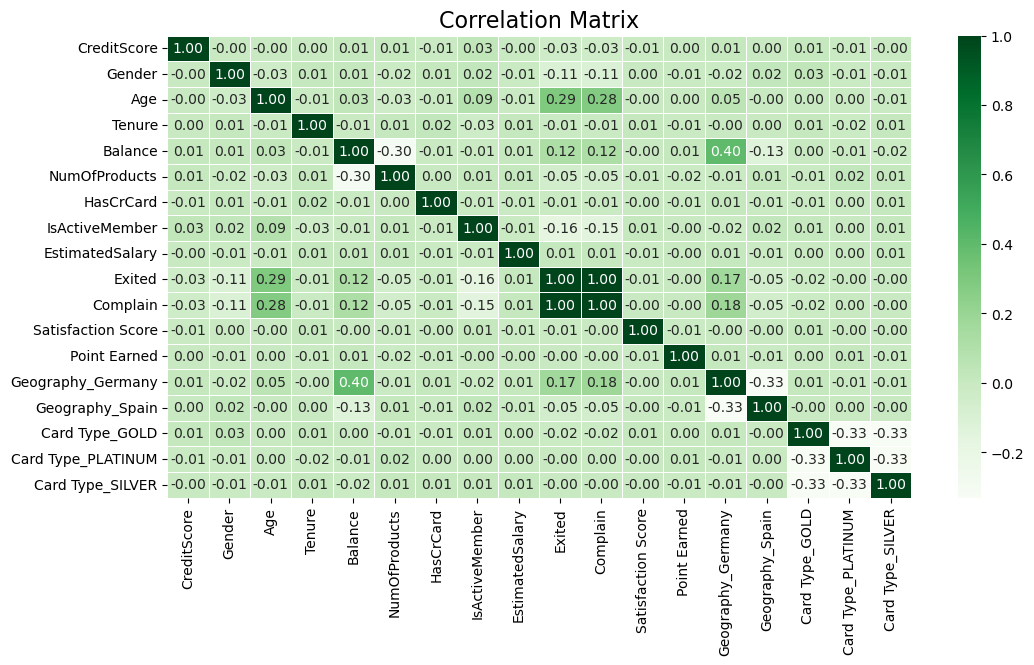

In [9]:
# Beginning Analyzation and visualization
corr = data_set.corr().round(2)
plt.figure(figsize=(12, 6))
sns.heatmap(corr, annot=True, cmap="Greens", linewidths=0.5, fmt=".2f")
plt.title("Correlation Matrix", fontsize=16)
plt.show()

<div dir = "rtl">
در این ماتریس با توجه به همبستگی متغیرها، می‌توانیم ببینیم که بین متغیر(Exited)   و متغیر (Complain) همبستگی ۱۰۰٪ای داریم یعنی قوی‌ترین عامل ترک مشتری از بانک به پارامتر شکایت (Complain) با همبستگی مثبت حدود ۰.۲۹ مربوط هست و بعد از آن سن (Age) با همبستگی مشابه ۰.۲۹ قرار دارد ، مشتریان مسن‌تر (اکثرا ۵۰ سال به بالا) ریسک بالاتری برای ریزش دارند.
</div>

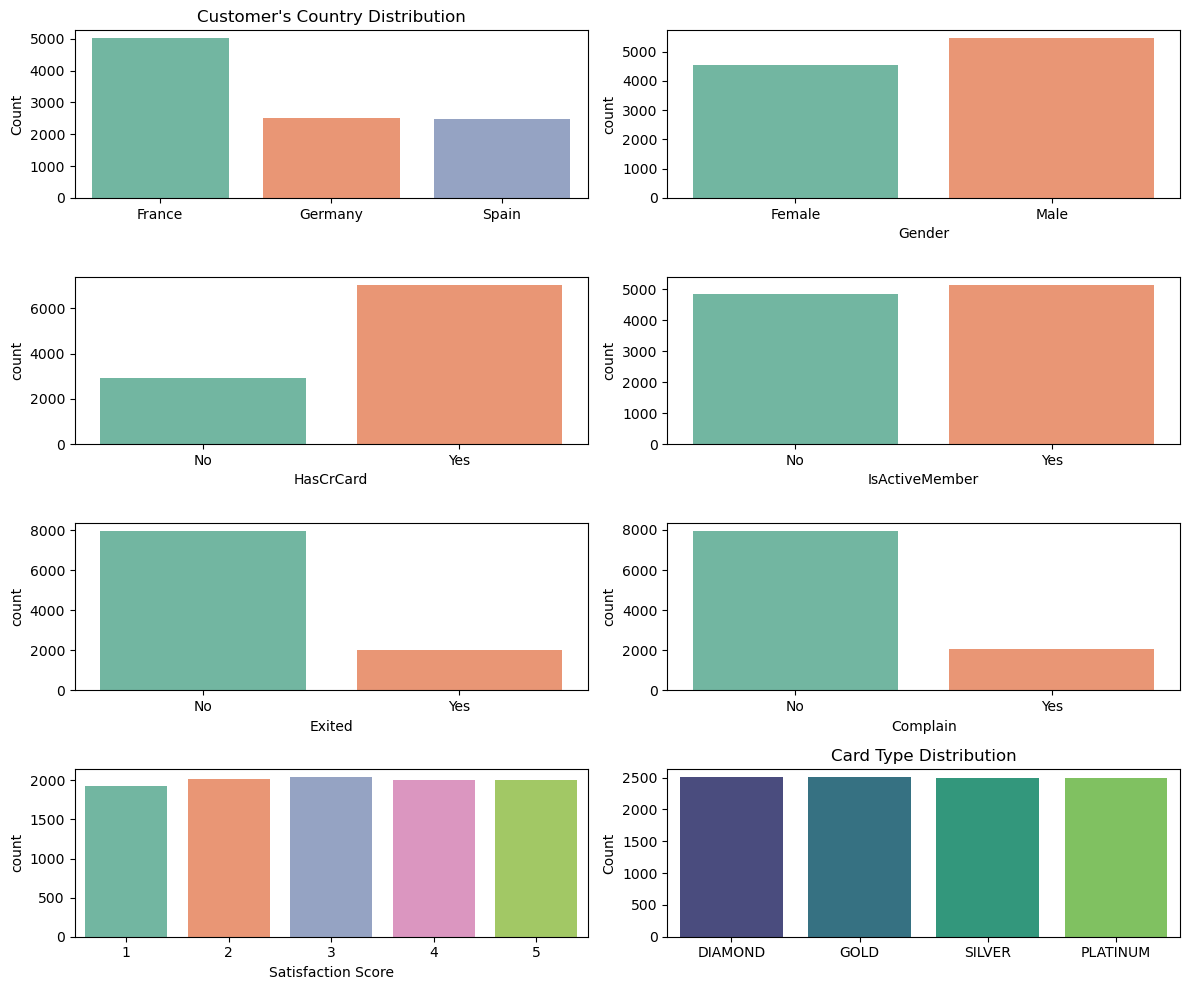

In [10]:
# Barplot - countplot - subplot

plt.figure(figsize=(12, 10))

country_counts = {
    "France": (
        (data_set["Geography_Germany"] == 0) & (data_set["Geography_Spain"] == 0)
    ).sum(),
    "Germany": data_set["Geography_Germany"].sum(),
    "Spain": data_set["Geography_Spain"].sum(),
}

plt.subplot(4, 2, 1)
sns.barplot(
    x=list(country_counts.keys()),
    y=list(country_counts.values()),
    hue=list(country_counts.keys()),
    palette="Set2",
    legend=False,
)
plt.ylabel("Count")
plt.title("Customer's Country Distribution")


plt.subplot(4, 2, 2)
sns.countplot(x="Gender", hue="Gender", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["Female", "Male"])


plt.subplot(4, 2, 3)
sns.countplot(
    x="HasCrCard", hue="HasCrCard", data=data_set, palette="Set2", legend=False
)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 4)
sns.countplot(
    x="IsActiveMember",
    hue="IsActiveMember",
    data=data_set,
    palette="Set2",
    legend=False,
)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 5)
sns.countplot(x="Exited", hue="Exited", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 6)
sns.countplot(x="Complain", hue="Complain", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 7)
sns.countplot(
    x="Satisfaction Score",
    hue="Satisfaction Score",
    data=data_set,
    palette="Set2",
    legend=False,
)

card_counts = {
    "DIAMOND": (
        (data_set["Card Type_GOLD"] == 0)
        & (data_set["Card Type_SILVER"] == 0)
        & (data_set["Card Type_PLATINUM"] == 0)
    ).sum(),
    "GOLD": data_set["Card Type_GOLD"].sum(),
    "SILVER": data_set["Card Type_SILVER"].sum(),
    "PLATINUM": data_set["Card Type_PLATINUM"].sum(),
}

plt.subplot(4, 2, 8)
sns.barplot(
    x=list(card_counts.keys()),
    y=list(card_counts.values()),
    hue=list(card_counts.keys()),
    palette="viridis",
    legend=False,
)
plt.title("Card Type Distribution")
plt.ylabel("Count")


plt.subplots_adjust(hspace=0.7, wspace=0.3)
plt.tight_layout()
plt.show()

<div dir = "rtl"> 
 بیشترین مشتریان این بانک از کشور فرانسه (حدود ۵۰۰۰ نفر) هستند، بعد آلمان (حدود ۲۵۰۰) و اسپانیا (حدود ۲۵۰۰) اما بیشترین ریزش مربوط به کشور آلمان بوده! که با توجه به یک نسبت و تناسب سر انگشتی این عنوان باید متعلف به فرانسه با مشتریان بیشتر باشد.


حدود ۷۰٪ مشتریان کارت اعتباری دارند که فکر میکنم در ایران باید درصد پایینی باشد، از آنجایی که سیستم پرداخت بین موبایل و کارتحوان ها در ایران فعال نشده است .

تقریباً نصف مشتریان فعال  و نصف غیرفعال  هستند که این نسبت بسیار بالایی است

تعداد بسیار کمی شکایت ثبت کرده‌اند حدود ۲۰۰۰ نفر از ۱۰۰۰۰، اما همان‌طور که قبلاً دیدیم، این گروه کوچک نرخ ریزش  بسیار بالایی دارد.

توزیع جنسیت و انواع کارت و  نمره رضایت نسبتاً متعادل است و به نظر نمی‌رسد ارتباطی میان این پارامتر ها و ریزش مشتریان وجود داشته باشد.

این نمودارها تأیید می‌کنند که ریزش بیشتر تحت تأثیر عوامل رفتاری مانند شکایت ، فعال بودن و محل جغرافیایی است تا توزیع جمعیتی پایه (مانند جنسیت یا نوع کارت)
</div>

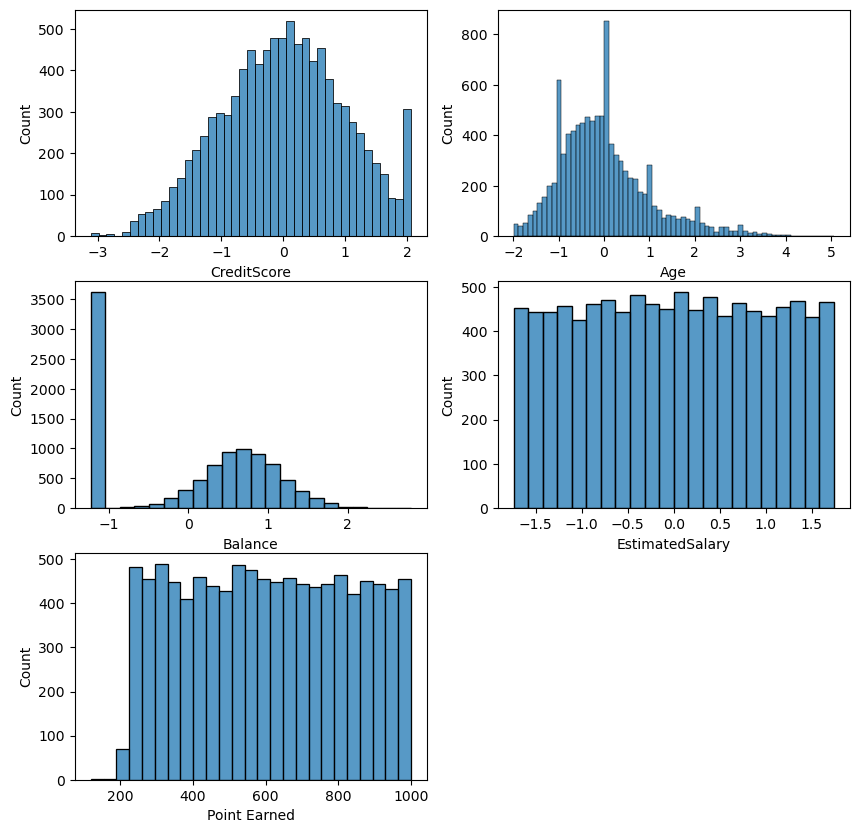

In [11]:
# histplot
plt.figure(figsize=(10, 10))

plt.subplot(3, 2, 1)
sns.histplot(x=data_set["CreditScore"], kde=False)

plt.subplot(3, 2, 2)
sns.histplot(x=data_set["Age"], kde=False)

plt.subplot(3, 2, 3)
sns.histplot(x=data_set["Balance"], kde=False)

plt.subplot(3, 2, 4)
sns.histplot(x=data_set["EstimatedSalary"], kde=False)

plt.subplot(3, 2, 5)
sns.histplot(x=data_set["Point Earned"], kde=False)
plt.show()

<div dir = "rtl"> 
با دقت به پارامتر دسته‌بندی شده حقوق حدودی، متوجه می‌شویم که تقریبا تعداد افراد یکسانی برای هر محدوده حقوق داریم

اکثر متغیرها به خوبی متعادل هستند، یک توزیع نرمال غیرکامل، و وقتی به متغیر balance نگاه می‌کنیم، می‌توانیم ببینیم که بیشتر داده‌های ما مربوط به افرادی است که در حساب‌های خود پول ندارند و کسانی که پول دارند، کاملاً متعادل هستند.

عدم تعادل شدید در Balance توضیح می‌دهد چرا ترکیب Balance بالا و  تعداد محصولات  کم، ریسک ریزش  را افزایش می‌دهد.

تمرکز  روی مشتریان مسن با بالانس بالا اما فعالیت کم منطقی‌ترین استراتژی است.
</div>

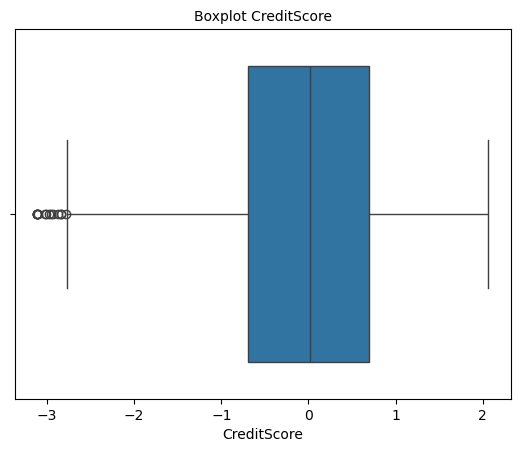

In [12]:
# boxplot
plt.title("Boxplot CreditScore", fontdict={"fontsize": 10})
sns.boxplot(x=data_set["CreditScore"])
plt.show()

<div dir = "rtl"> 
با نگاهی به نمودارهای باکس‌پلات متغیرهای پیوسته، می‌بینیم که داده‌های پرت کمی داریم، فعلاً آنها را در نظر نمی‌گیریم.
</div>

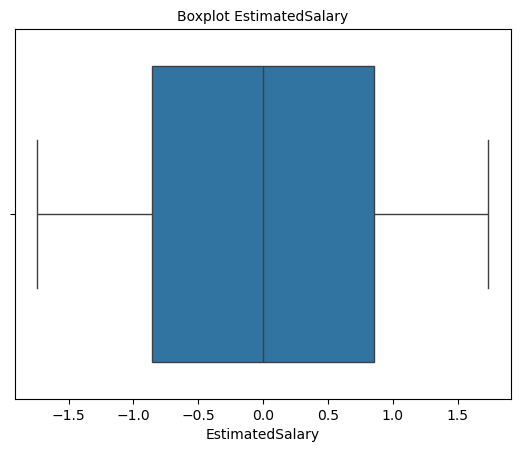

In [13]:
plt.title("Boxplot EstimatedSalary", fontdict={"fontsize": 10})
sns.boxplot(x=data_set["EstimatedSalary"])
plt.show()

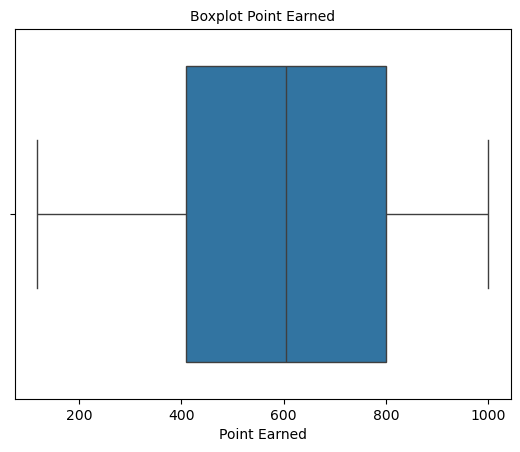

In [14]:
plt.title("Boxplot Point Earned", fontdict={"fontsize": 10})
sns.boxplot(x=data_set["Point Earned"])
plt.show()

c:\Anaconda\Lib\site-packages\matplotlib\_tight_bbox.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  fig.patch.set_bounds(x0 / w1, y0 / h1,
c:\Anaconda\Lib\site-packages\matplotlib\_tight_bbox.py:68: RuntimeWarning: divide by zero encountered in scalar divide
  fig.bbox.width / w1, fig.bbox.height / h1)
c:\Anaconda\Lib\site-packages\matplotlib\patches.py:797: RuntimeWarning: invalid value encountered in scalar add
  y1 = self.convert_yunits(self._y0 + self._height)
c:\Anaconda\Lib\site-packages\matplotlib\transforms.py:2037: RuntimeWarning: invalid value encountered in scalar add
  self._mtx[1, 2] += ty
c:\Anaconda\Lib\site-packages\matplotlib\transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


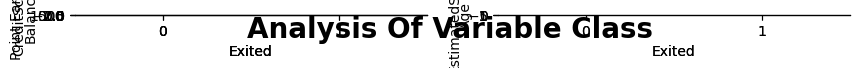

In [15]:
plt.figure(figsize=(10, 0))
plt.suptitle("Analysis Of Variable Class", fontweight="bold", fontsize=20)

plt.subplot(3, 2, 1)
sns.boxplot(x="Exited", y="CreditScore", data=data_set)

plt.subplot(3, 2, 2)
sns.boxplot(x="Exited", y="Age", data=data_set)

plt.subplot(3, 2, 3)
sns.boxplot(x="Exited", y="Balance", data=data_set)

plt.subplot(3, 2, 4)
sns.boxplot(x="Exited", y="EstimatedSalary", data=data_set)

plt.subplot(3, 2, 5)
sns.boxplot(x="Exited", y="Point Earned", data=data_set)
plt.show()

<div dir = "rtl"> 
این باکس‌پلات ها تأیید می‌کنند که ریزش در این دیتاست بیشتر یک مسئله جمعیتی- رفتاری است (سن بالا + موجودی بالا + احتمالاً عدم فعالیت یا شکایت) تا مالی-اعتباری (امتیاز اعتباری یا حقوق).

از نظر من با انجام این کار ها احتمال ترک و ریزش مشتری های بانک کاهش میابد:
- پیگیری،رسیدگی و رفع و رجوع آن ها(از آنجایی که مهم ترین عامل نرخ شکایت ها بود!)
- تمرکز بیشتر روی مشتری های میان سال و بازنشسته ها برای جذب آن ها، ارائه برنامه های آموزشی جهت استفاده آسان تر آن ها از خدمات بانک، ارائه و تبلیغات پکیج های جذاب برای بازنشستگان 
- پیگیری علت ریزش بیش از حد مشتریان آلمانی و استفاده از خود آلمانی های محلی برای ارائه پیشنهادهای ویژه برای بازار آلمان و جذب دوباره مشتریان
- در نظر گرفتن پاداش (جایزه واقعی ) برای نمرات و امتیاز های اعتباری مشتریان (مانند تخفیف، گیفت‌کارت، نرخ بهره بالاتر و ...) جهت تشویق به فعالیت بیشتر مشتریان

</div>
